In [1]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "qiskit-machine-learning==0.9.0" "koreanize-matplotlib==0.1.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
# ============================================
# 암호화폐 데이터 (30개)
# [return%, volatility%, trade_volume(M$), spread(bps), social_sentiment(-1~1), max_drawdown%, momentum]
# ============================================

crypto_data = np.array([
 [1.8,18.0,900,30,0.4,14.5,1.2],
 [2.2,22.0,850,45,0.2,18.0,1.4],
 [1.5,15.5,920,25,0.5,13.8,0.9],
 [2.8,28.0,780,55,0.1,22.1,1.8],
 [1.3,13.0,950,20,0.6,11.9,0.7],
 [1.7,17.5,910,28,0.3,15.1,1.0],
 [2.5,25.0,800,48,0.2,19.3,1.6],
 [1.2,12.5,970,18,0.7,10.8,0.6],
 [1.9,19.0,880,35,0.4,15.5,1.1],
 [2.6,26.5,790,52,0.1,20.7,1.7],
 [1.4,14.0,940,22,0.5,12.3,0.8],
 [1.8,18.5,900,31,0.3,16.0,1.0],
 [2.1,21.0,860,43,0.2,17.5,1.3],
 [1.1,11.0,980,16,0.8, 9.8,0.5],
 [2.7,27.0,770,56,0.0,21.8,1.9],
 [1.5,15.0,930,26,0.5,13.5,0.9],
 [2.3,23.0,830,47,0.1,18.9,1.5],
 [1.0,10.5,990,14,0.9, 9.0,0.4],
 [2.0,20.0,870,39,0.3,16.8,1.2],
 [1.3,13.5,950,23,0.6,12.0,0.7],
 [2.4,24.5,820,50,0.1,19.6,1.6],
 [1.9,19.5,880,33,0.4,15.8,1.1],
 [1.6,16.0,910,27,0.4,14.0,1.0],
 [2.2,22.5,840,46,0.2,18.3,1.4],
 [1.1,11.5,970,17,0.8,10.2,0.6],
 [2.8,28.5,760,58,0.0,22.4,1.9],
 [1.5,15.8,930,25,0.5,13.6,0.9],
 [2.3,23.5,820,49,0.1,19.0,1.5],
 [1.0,10.0,995,13,0.9, 8.8,0.4],
 [2.6,26.0,780,54,0.1,21.2,1.7],
], dtype=np.float32)

암호화폐 바스켓 비용 VQE 후보: ['A'] 목적값: 0.342856
암호화폐 바스켓 비용 QAOA 후보: ['D'] 목적값: 0.337922


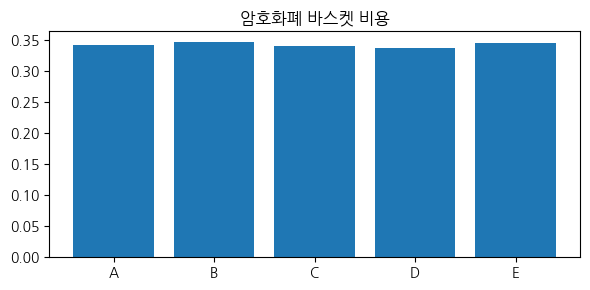

In [5]:
# QNN·VQE·QAOA 실행 코드
crypto_report = extension_problem('암호화폐', crypto_data)
compare_baskets(crypto_report, '암호화폐 바스켓 비용')

In [6]:
# 추가 실습 코드 — 거래량과 스프레드 분리 비교
normalized_crypto = np.column_stack([minmax(crypto_data[:,j]) for j in range(7)])
for label, alternative_friction in [
    ('거래량만 반영', 1-normalized_crypto[:,2]),
    ('스프레드만 반영', normalized_crypto[:,3]),
    ('둘 다 반영', crypto_report['friction'])]:
    alternative_cost = (0.5*crypto_report['risk']+0.3*alternative_friction
                        -0.2*normalized_crypto[:,0]+0.05*(1-normalized_crypto[:,4])
                        +0.05*(1-normalized_crypto[:,6]))
    basket_values = alternative_cost.reshape(5,6).mean(axis=1)
    print(label, basket_values.round(4), '최저 바스켓:', list('ABCDE')[int(np.argmin(basket_values))])

거래량만 반영 [0.3409 0.3479 0.3369 0.3391 0.3481] 최저 바스켓: C
스프레드만 반영 [0.3393 0.3433 0.3448 0.3457 0.3493] 최저 바스켓: A
둘 다 반영 [0.349  0.3514 0.3413 0.345  0.3499] 최저 바스켓: C
